# LAB 05 — RNN, LSTM và GRU
Nguyễn Huy Sơn — 23001922

Kết quả thực nghiệm ngày 15/10/2026 trên toàn bộ IMDb đã làm sạch.

Bài tính viết tay: [calculations.pdf](calculations.pdf). Dự đoán theo cơ chế: [prediction.md](prediction.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from experiments import run_all
from preprocessing import tokenize, encode
from rnn_cell import check_framework_parity
from predict import SentimentPredictor

ROOT = Path.cwd()
if not (ROOT / "experiments.py").exists():
    raise RuntimeError("Chạy notebook trong thư mục lab5_nlp.")
OUT = ROOT / "artifacts"
if not (OUT / "run_manifest.json").exists() or not (ROOT / "results.csv").exists():
    run_all()
manifest = json.loads((OUT / "run_manifest.json").read_text())
if "completed_at_utc" not in manifest:
    run_all()
    manifest = json.loads((OUT / "run_manifest.json").read_text())
results = pd.read_csv(ROOT / "results.csv")
display(pd.Series({key: manifest[key] for key in ["device", "gpu", "python", "torch", "started_at_utc", "completed_at_utc"]}))
display(pd.Series(manifest["config"]))

device                                            cuda
gpu                 NVIDIA GeForce RTX 4050 Laptop GPU
python                                          3.13.9
torch                                      2.6.0+cu124
started_at_utc        2026-10-15T03:04:08.954982+00:00
completed_at_utc      2026-10-15T03:08:39.424760+00:00
dtype: object

seed                   42
epochs                  8
batch_size            128
embedding_dim         100
hidden_size            64
dropout               0.2
learning_rate       0.001
weight_decay          0.0
gradient_clip         1.0
vocabulary_limit    20000
min_frequency           2
threshold             0.5
num_layers              1
bidirectional       False
dtype: object

## 1. Dataset và độ dài sequence

source                          /home/sonnh/Documents/btvn/nlp/lab04_nlp/imdb.zip
source_sha256                   73a235bc5fc4df57bb5d517afa480fe6bfd4e2afc25dc5...
raw_samples                                                                 50000
classes                                                                         2
raw_class_counts                           {'positive': 25000, 'negative': 25000}
missing_text                                                                    0
missing_labels                                                                  0
empty_text                                                                      0
exact_duplicate_reviews                                                       418
normalized_duplicate_reviews                                                  422
conflicting_texts                                                               0
clean_samples                                                               49578
removed_rows    

,split,samples,negative,positive,min_length,median_length,mean_length,p90_length,p95_length,max_length,oov_token_percent
0,train,29746,14817,14929,9,173.0,230.101392,448.0,588.00,2462,2.665197
1,validation,9916,4939,4977,6,173.0,230.066357,452.0,583.25,2113,2.900359
2,test,9916,4940,4976,6,171.0,229.209964,449.0,589.00,2115,2.919072


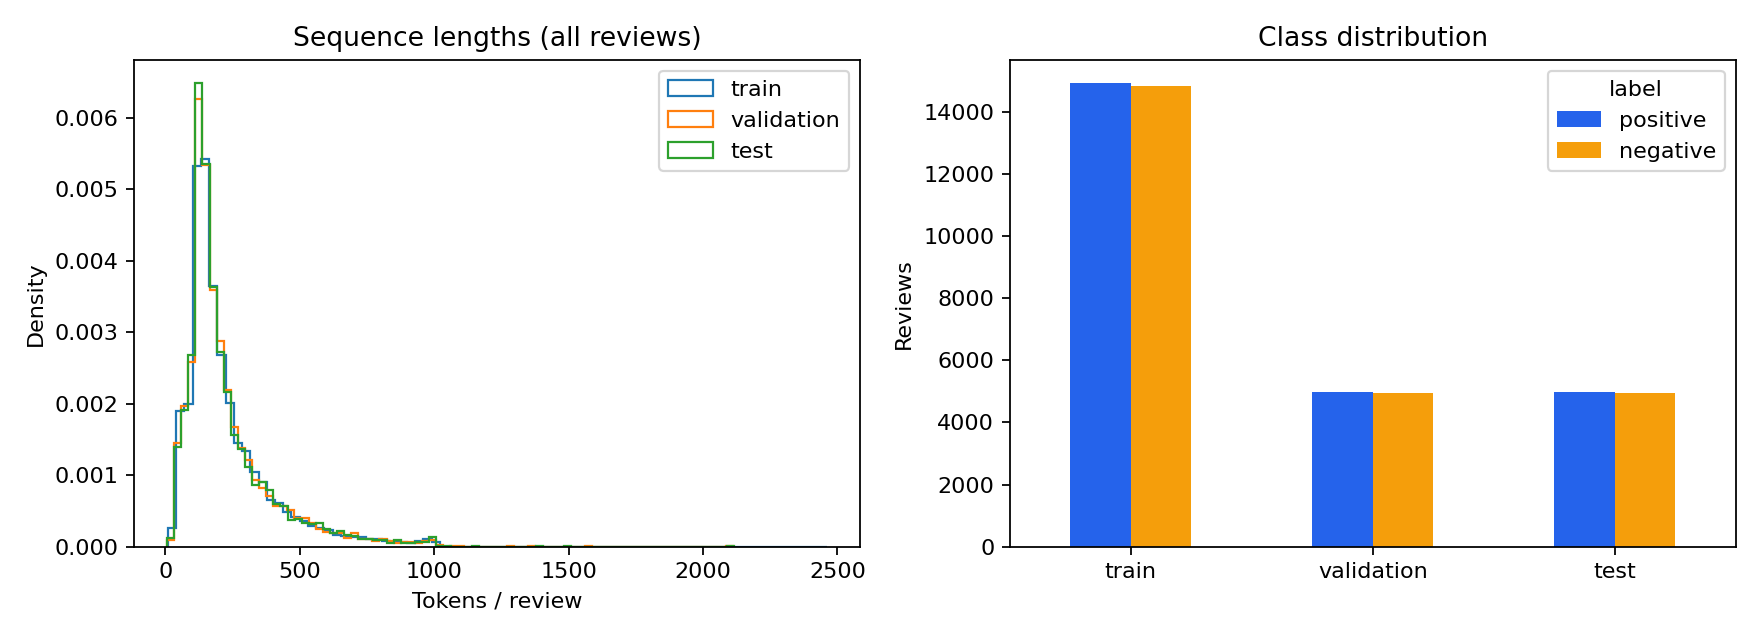

In [2]:
inspection = json.loads((ROOT / "data/inspection.json").read_text())
display(pd.Series({key: value for key, value in inspection.items() if key not in ["split_sha256", "tokenizer"]}))
display(pd.read_csv(ROOT / "data/split_summary.csv"))
display(Image(filename=str(ROOT / "sequence_lengths.png")))

Dữ liệu gốc có 50.000 review, hai lớp cân bằng, không thiếu text/label. Loại 422 bản trùng sau chuẩn hóa còn 49.578 mẫu. Train có median 173, mean 230,10 và p95 588 token; cần xem phân bố độ dài và tỉ lệ token giữ lại khi chọn max_length.

Với train, length 50/100/200 giữ lần lượt 21,63%/41,74%/68,81% tổng token. Chọn 200 trong phạm vi khảo sát để giữ nhiều context hơn, nhưng vẫn cắt khoảng 40,80% review. Mốc 30 chỉ giữ 13,03% tổng token; phần kết luận hoặc chuyển ý ở cuối dễ bị mất.

## 2. Tokenizer, vocabulary, padding và truncation
`PAD=0`, `UNK=1`. Vocabulary chỉ học trên train; giữ stopwords và phủ định. Cắt từ bên phải; padding ở bên phải. Model lấy timestep cuối có token thật.

In [3]:
import torch
from models import collate_reviews

vocabulary = json.loads((OUT / "vocabulary.json").read_text())
texts = ["I really like this movie", "I do not like it"]
sequences = [encode(text, vocabulary, max_length=100) for text in texts]
padded, lengths, _ = collate_reviews([(torch.tensor(ids), torch.tensor(0.)) for ids in sequences])
display(pd.DataFrame({"text": texts, "tokens": [tokenize(text) for text in texts], "ids": sequences}))
print("Padded:", padded.tolist())
print("Lengths:", lengths.tolist(), "Vocabulary:", len(vocabulary))
display(pd.read_csv(ROOT / "data/token_retention.csv"))

,text,tokens,ids
0,I really like this movie,"[i, really, like, this, movie]","[10, 65, 37, 11, 16]"
1,I do not like it,"[i, do, not, like, it]","[10, 76, 21, 37, 9]"


Padded: [[10, 65, 37, 11, 16], [10, 76, 21, 37, 9]]
Lengths: [5, 5] Vocabulary: 20000


,split,max_length,tokens_retained_percent,mean_document_retained_percent,truncated_documents_percent
0,train,30,13.030762,19.750911,99.761312
1,train,50,21.631678,32.340174,97.434949
2,train,100,41.742157,58.361652,87.265515
3,train,200,68.811644,84.835189,40.802125
4,validation,30,13.033097,19.638766,99.778136
5,validation,50,21.641028,32.198633,97.519161
6,validation,100,41.805993,58.273783,87.676482
7,validation,200,68.945812,84.893634,40.611134
8,test,30,13.079989,19.728308,99.717628
9,test,50,21.716738,32.314842,97.478822


Padding thêm PAD để ghép batch, không bổ sung nội dung ngôn ngữ. Truncation bỏ token vượt giới hạn nên có thể mất thông tin. Model lấy hidden tại token thật cuối, tránh dùng hidden sau các PAD. Vocabulary chỉ học trên train để tránh rò rỉ dữ liệu.

## 3. Simple RNN cell
Source: `rnn_cell.py`. Kiểm tra bằng input ngẫu nhiên riêng, so sánh cả forward và gradient với `torch.nn.RNNCell`.

In [4]:
import inspect
from rnn_cell import SimpleRNNCell

print(inspect.getsource(SimpleRNNCell))
display(pd.Series(check_framework_parity()))

class SimpleRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.weight_ih = nn.Parameter(torch.empty(hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.bias = nn.Parameter(torch.zeros(hidden_size))
        bound = hidden_size ** -0.5
        nn.init.uniform_(self.weight_ih, -bound, bound)
        nn.init.uniform_(self.weight_hh, -bound, bound)

    def forward(self, x_t, h_prev):
        return torch.tanh(x_t @ self.weight_ih.T + h_prev @ self.weight_hh.T + self.bias)



output_max_abs_error             0.0
input_gradient_max_abs_error     0.0
hidden_gradient_max_abs_error    0.0
batch_size                       2.0
input_size                       3.0
hidden_size                      4.0
dtype: float64

`x_t` là embedding hiện tại, `h_prev` là trạng thái từ các token trước. Hai phép nhân ma trận đưa chúng về cùng không gian hidden; cộng bias rồi qua `tanh` để tạo `h_t`. Các trọng số dùng chung ở mọi timestep. Vì `h_t` phụ thuộc `h_prev`, hai câu cùng từ nhưng khác thứ tự có thể tạo trạng thái cuối khác nhau.

Khi đọc `like`, thông tin `not` từ bước trước có thể làm thay đổi cách biểu diễn cảm xúc. Average Word2Vec lấy trung bình nên không giữ quan hệ thứ tự trực tiếp. Với câu dài, trạng thái cuối có thể mất chi tiết ở xa; gradient truyền qua nhiều bước có thể rất nhỏ hoặc rất lớn. Gradient clipping hạn chế gradient quá lớn, không giải quyết triệt để vanishing gradient.

### LSTM gates và GRU

Forget gate điều chỉnh lượng cell state cũ được giữ; input gate điều chỉnh thông tin mới; output gate điều chỉnh phần cell state đưa ra hidden state. Forget gate gần 1 giữ nhiều thông tin cũ, gần 0 loại phần lớn thông tin đó. Đường cập nhật cell state giúp LSTM truyền thông tin qua nhiều bước, nhưng không đảm bảo nhớ mọi dependency.

GRU dùng update/reset gate và không có cell state riêng. Tại cùng hidden size, GRU có ít tham số hơn LSTM: 2.031.937 so với 2.042.561, tính cả embedding; RNN có 2.010.689 tham số.

### Prediction

Tóm tắt dự đoán theo cơ chế để đối chiếu với thực nghiệm đã chạy.

| Câu | Prediction | Reason | Confidence |
|---|---|---|---|
| 1 | RNN xử lý thứ tự từ trực tiếp hơn TF-IDF + LR. | Hidden state cập nhật theo từng token; TF-IDF unigram không giữ thứ tự, bigram chỉ giữ quan hệ cục bộ. | Cao |
| 2 | LSTM có khả năng giữ dependency dài tốt hơn RNN thường. | Cell state và các gate điều chỉnh việc giữ, thêm và xuất thông tin; kết quả còn phụ thuộc dữ liệu và huấn luyện. | Cao về cơ chế; trung bình về mức tăng metrics |
| 3 | Tăng length từ 50 lên 200 thường làm RNN tốn thời gian và bộ nhớ hơn. | Có nhiều timestep cần xử lý và truyền gradient; dependency xa cũng khó học hơn. | Cao về chi phí; trung bình về độ khó tối ưu |
| 4 | Cắt review còn 30 token có thể làm giảm chất lượng classification. | Nhận xét cuối, phủ định hoặc đoạn chuyển ý có thể nằm sau phần được giữ. | Cao |
| 5 | LSTM không đảm bảo accuracy cao hơn RNN trên mọi dataset. | Dữ liệu, độ dài, nhiễu và hyperparameter ảnh hưởng kết quả; model đơn giản vẫn có thể phù hợp hơn. | Cao |


## 4. Baseline và so sánh architecture
TF-IDF + LR dùng cấu hình đã chọn từ Lab 04, đọc review đầy đủ. Các recurrent model so sánh tại `max_length=100`, cùng cấu hình huấn luyện. `training_seconds` của recurrent gồm train, validation và lưu checkpoint; không gồm chuẩn bị dữ liệu hoặc test.

In [5]:
columns = ["model", "parameters", "vocabulary_size", "epochs", "best_epoch", "validation_f1",
           "training_seconds", "accuracy", "precision", "recall", "f1", "macro_f1"]
display(pd.read_csv(OUT / "architecture_comparison.csv")[columns].round(4))

,model,parameters,vocabulary_size,epochs,best_epoch,validation_f1,training_seconds,accuracy,precision,recall,f1,macro_f1
0,TFIDF_LR,50001,50000,NaN,NaN,0.9030,22.3390,0.9081,0.8985,0.9210,0.9096,0.9081
1,RNN_len100,2010689,20000,8.0,7.0,0.7531,12.4278,0.7304,0.6949,0.8252,0.7544,0.7278
2,LSTM_len100,2042561,20000,8.0,8.0,0.8246,18.3489,0.8199,0.7828,0.8873,0.8318,0.8190
3,GRU_len100,2031937,20000,8.0,8.0,0.8301,14.3738,0.8200,0.7928,0.8682,0.8288,0.8195


Tại length 100, F1 của RNN/LSTM/GRU là 0,7544/0,8318/0,8288; accuracy tương ứng 0,7304/0,8199/0,8200. GRU có accuracy nhỉnh hơn LSTM rất nhỏ nhưng F1 thấp hơn, nên không thể xếp hạng chỉ từ accuracy. Các model gated tốt hơn RNN trong lần chạy này, phù hợp với kỳ vọng về khả năng giữ context, nhưng chưa chứng minh riêng cơ chế nào tạo ra mức tăng.

TF-IDF + LR đạt F1 0,9096, cao hơn cả các recurrent model đã thử. Baseline đọc toàn bộ review còn recurrent bị truncate, nên đây không phải phép so sánh cùng lượng context. Kết quả không ủng hộ nhận định model sequence luôn tốt hơn model tĩnh.

## 5. Thay đổi max_length
9 cấu hình: 3 architecture × 3 độ dài. Chọn checkpoint bằng F1 validation; threshold 0.5. Mỗi cấu hình chạy đủ 8 epoch. `% tokens retained` là tổng token giữ lại / tổng token gốc trên train.

,model,max_length,tokens_retained_percent,validation_loss,validation_f1,training_seconds,peak_gpu_allocated_mb,accuracy,f1
0,TFIDF_LR,NaN,NaN,0.2705,0.9030,22.3390,NaN,0.9081,0.9096
1,RNN_len50,50.0,21.6317,0.6025,0.7391,14.7567,136.0508,0.7104,0.7421
2,RNN_len100,100.0,41.7422,0.6063,0.7531,12.4278,175.6104,0.7304,0.7544
3,RNN_len200,200.0,68.8116,0.5138,0.7831,25.3705,254.1299,0.7774,0.7872
4,LSTM_len50,50.0,21.6317,0.6824,0.7823,14.8908,153.6123,0.7722,0.7842
5,LSTM_len100,100.0,41.7422,0.5697,0.8246,18.3489,207.8511,0.8199,0.8318
6,LSTM_len200,200.0,68.8116,0.4480,0.8539,14.4413,317.0615,0.8600,0.8638
7,GRU_len50,50.0,21.6317,0.7191,0.7840,13.3066,152.7856,0.7686,0.7819
8,GRU_len100,100.0,41.7422,0.6661,0.8301,14.3738,207.1836,0.8200,0.8288
9,GRU_len200,200.0,68.8116,0.3827,0.8612,13.7184,317.0972,0.8562,0.8606


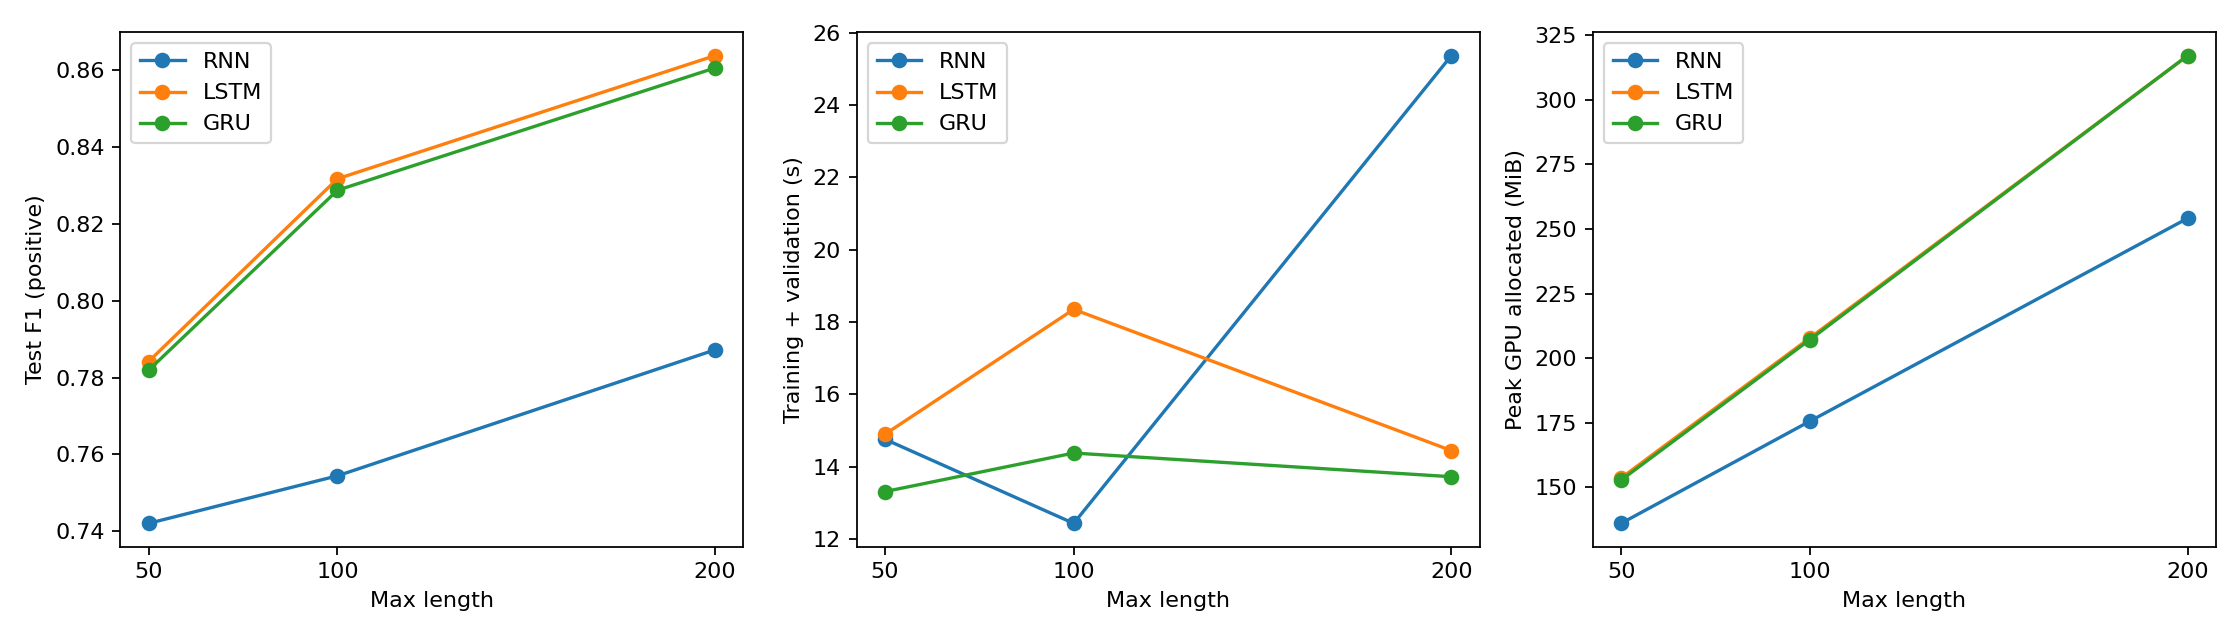

In [6]:
display(results[["model", "max_length", "tokens_retained_percent", "validation_loss", "validation_f1",
                 "training_seconds", "peak_gpu_allocated_mb", "accuracy", "f1"]].round(4))
display(Image(filename=str(ROOT / "sequence_length_comparison.png")))

Với LSTM, length 50 → 100 → 200 làm test F1 tăng 0,7842 → 0,8318 → 0,8638; GPU memory tăng khoảng 153,61 → 207,85 → 317,06 MiB. RNN và GRU cũng tăng F1 trong ba mốc đã thử. Chưa thể kết luận tăng length luôn cải thiện performance ngoài phạm vi này.

Thời gian LSTM đo được là 14,89/18,35/14,44 giây, không tăng đơn điệu; GRU cũng dao động nhẹ. Do chỉ đo một lần, không thể dùng các số này để kết luận length lớn chạy nhanh hơn. RNN 50 → 200 tăng từ 14,76 lên 25,37 giây. Trade-off context/bộ nhớ thể hiện rõ hơn trade-off thời gian trong run này; cần đo lặp để so sánh tốc độ chắc chắn hơn.

## 6. Learning curves

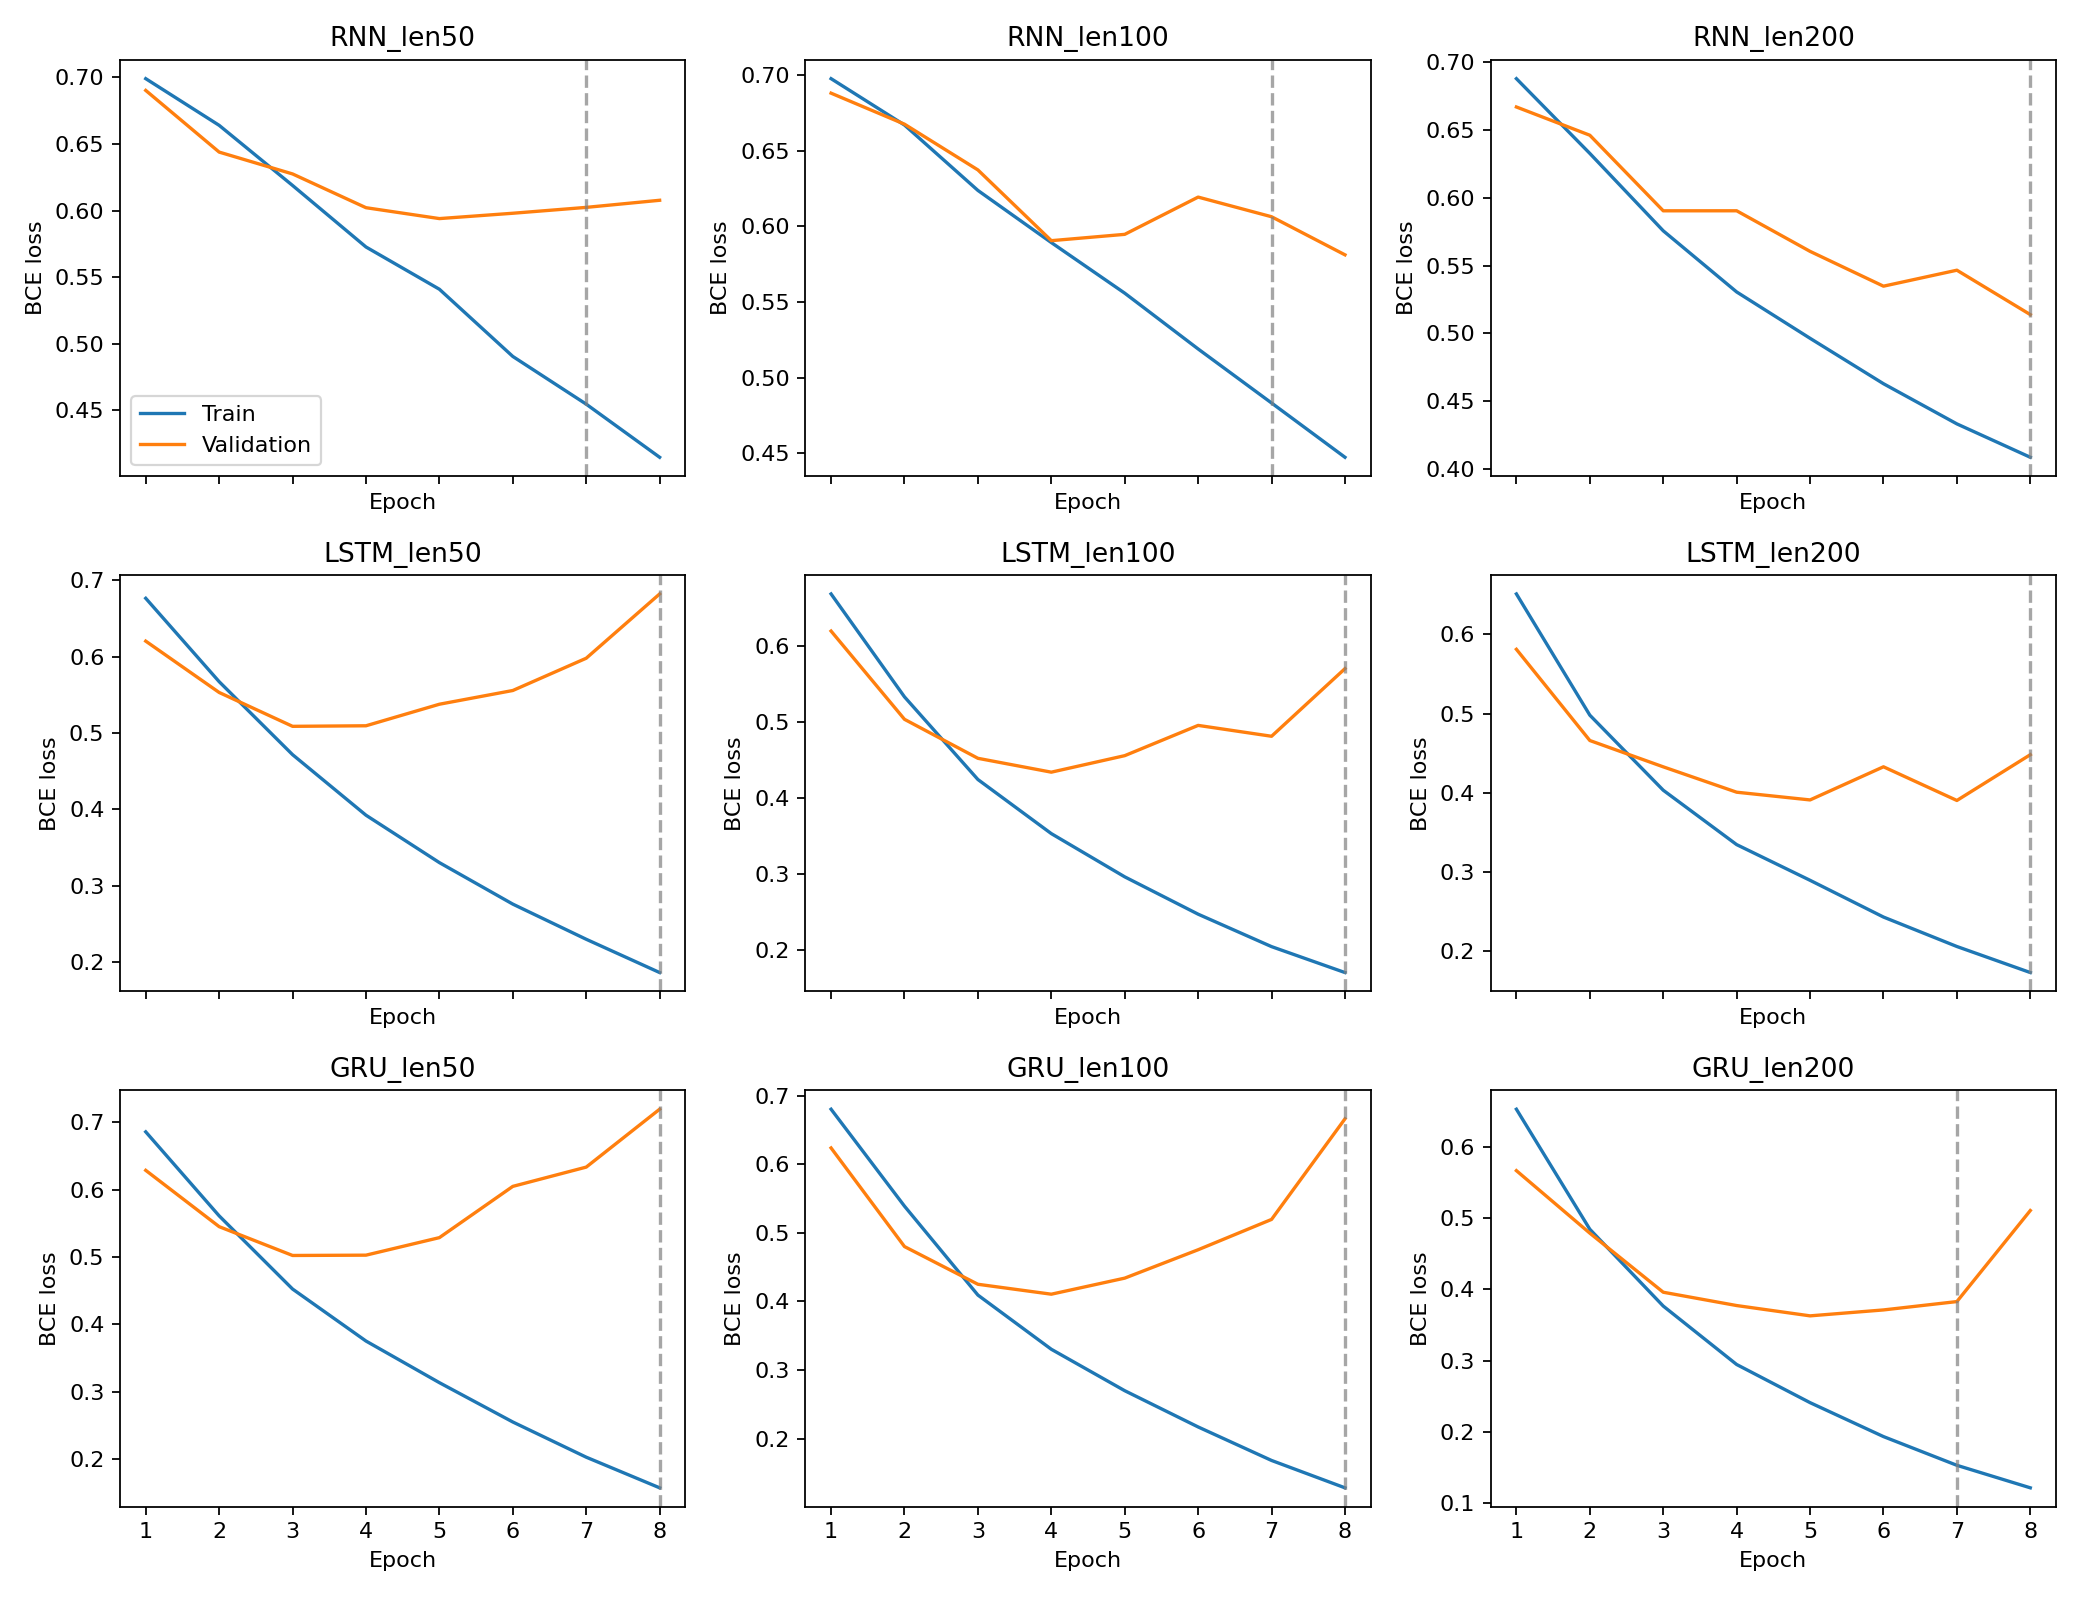

,model,epoch,train_loss,validation_loss,validation_f1
0,RNN_len50,1,0.6991,0.6903,0.5588
1,RNN_len50,2,0.6641,0.6440,0.6570
2,RNN_len50,3,0.6189,0.6276,0.6772
3,RNN_len50,4,0.5727,0.6022,0.6839
4,RNN_len50,5,0.5410,0.5940,0.7021
...,...,...,...,...,...
67,GRU_len200,4,0.2945,0.3771,0.8509
68,GRU_len200,5,0.2411,0.3627,0.8434
69,GRU_len200,6,0.1935,0.3710,0.8612
70,GRU_len200,7,0.1532,0.3827,0.8612


In [7]:
display(Image(filename=str(ROOT / "learning_curves.png")))
histories = pd.concat([pd.read_csv(OUT / name / "history.csv").assign(model=name)
                       for name in results.loc[results.architecture.isin(["RNN", "LSTM", "GRU"]), "model"]], ignore_index=True)
display(histories[["model", "epoch", "train_loss", "validation_loss", "validation_f1"]].round(4))

Nhiều model có train loss tiếp tục giảm trong khi validation loss tăng. Ví dụ GRU-200: validation loss thấp nhất khoảng 0,3627 ở epoch 5, tăng lên 0,5103 ở epoch 8; train loss giảm từ 0,2411 xuống 0,1217. Đây là dấu hiệu overfitting theo loss.

Checkpoint ứng dụng ở epoch 7 vì F1 validation cao nhất, không phải vì loss thấp nhất. Loss đo cả độ tin cậy xác suất, còn F1 dùng nhãn sau threshold 0,5 nên hai tiêu chí có thể chọn epoch khác nhau. LSTM/GRU length 50 và 100 cũng có khoảng cách train/validation tăng về cuối; không nên chỉ nhìn epoch cuối hoặc train loss.

## 7. Confusion matrix
Trục dọc: nhãn thật. Trục ngang: nhãn dự đoán. Positive là lớp dương khi tính precision/recall/F1.

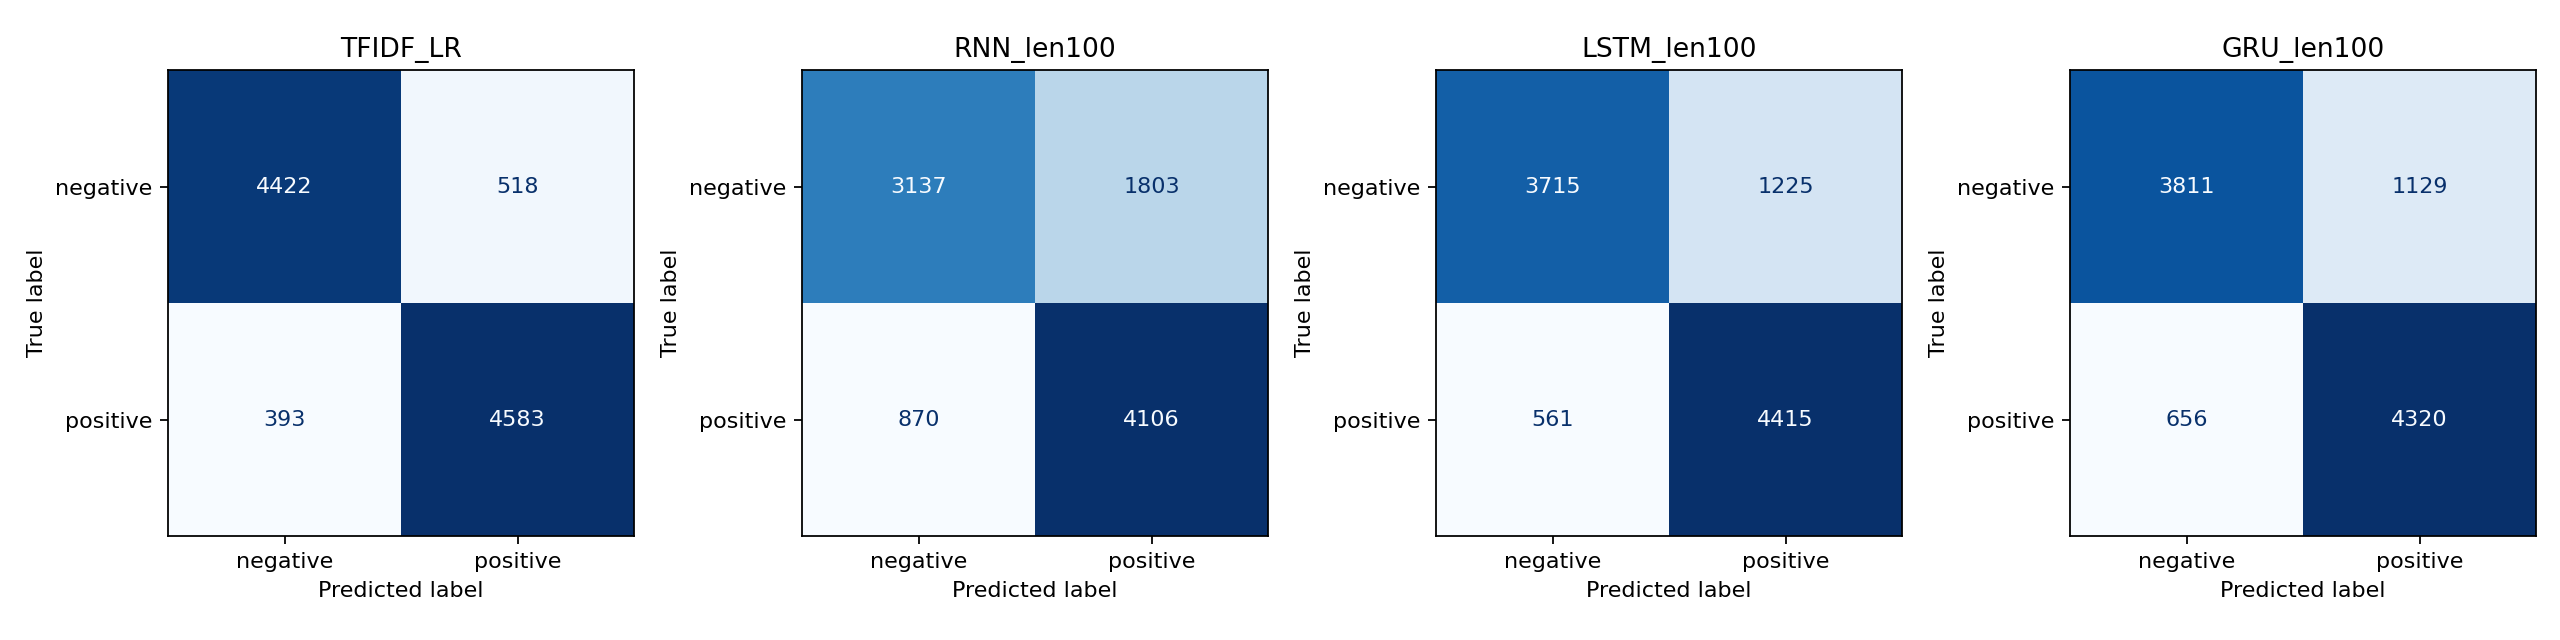

In [8]:
display(Image(filename=str(ROOT / "confusion_matrix.png")))

Tại length 100, false positive/false negative của RNN là 1.803/870, LSTM là 1.225/561, GRU là 1.129/656. Các model đều nhầm negative thành positive nhiều hơn chiều ngược lại; cần xem cả precision và recall để nhận ra xu hướng này.

GRU-200 được chọn bằng F1 validation 0,8612; test accuracy 0,8562, precision 0,8377, recall 0,8848 và F1 0,8606. LSTM-200 có test F1 0,8638 cao hơn một chút, nhưng không đổi lựa chọn model dựa trên test.

## 8. Kiểm tra thứ tự từ
512 review test cố định. So sánh 100 token đầu với phiên bản xáo trộn đúng các token đó, giữ nguyên model. Các ví dụ `dog bites man` chỉ ghi xác suất sentiment, không dùng để đánh giá hiểu ngữ nghĩa. TF-IDF baseline có bigram nên cũng có thể đổi dự đoán khi đảo từ.

In [9]:
display(pd.read_csv(OUT / "order_pair_predictions.csv").pivot(index="text", columns="model", values="positive_probability").round(4))
display(pd.read_csv(OUT / "order_shuffle_metrics.csv").round(4))

model,GRU_len200,LSTM_len200,RNN_len200,TFIDF_LR
text,,,,
dog bites man,0.2624,0.3311,0.2542,0.4484
man bites dog,0.1397,0.3367,0.1709,0.4484
the movie was bad but the ending was good,0.1950,0.3346,0.1793,0.1486
the movie was good but the ending was bad,0.1168,0.1048,0.0708,0.1422
this movie is good,0.6322,0.4967,0.4792,0.8007
this movie is not good,0.3019,0.3081,0.3429,0.0856


,model,order,samples,accuracy,precision,recall,f1,macro_f1
0,TFIDF_LR,original,512,0.8418,0.8237,0.8774,0.8497,0.8414
1,TFIDF_LR,shuffled,512,0.8398,0.8231,0.8736,0.8476,0.8394
2,RNN_len200,original,512,0.7500,0.7454,0.7739,0.7594,0.7496
3,RNN_len200,shuffled,512,0.7598,0.7500,0.7931,0.7709,0.7592
4,LSTM_len200,original,512,0.8184,0.8022,0.8544,0.8275,0.8179
5,LSTM_len200,shuffled,512,0.8086,0.7921,0.8467,0.8185,0.8080
6,GRU_len200,original,512,0.8223,0.8014,0.8659,0.8324,0.8216
7,GRU_len200,shuffled,512,0.8281,0.8100,0.8659,0.8370,0.8276


Trên 512 review với cùng 100 token đầu, xáo trộn làm F1 LSTM-200 giảm từ 0,8275 xuống 0,8185; RNN-200 và GRU-200 lại tăng nhẹ. TF-IDF bigram giảm từ 0,8497 xuống 0,8476. Kết quả cho thấy prediction phụ thuộc cách sắp xếp token, nhưng chưa chứng minh mọi recurrent model tận dụng thứ tự tốt hơn baseline.

Khả năng cập nhật hidden theo thứ tự là thuộc tính kiến trúc; lợi ích classification phải được kiểm tra bằng dữ liệu. Các câu `dog bites man` chỉ là probe sentiment, không phải bài kiểm tra model hiểu vai nghĩa của câu.

## 9. Vị trí từ khóa và long-range dependency
Giữ cùng độ dài và mẫu nền lặp; thay một token nền bằng từ khóa tại mỗi vị trí. Đổi vị trí `excellent`/`terrible` ở đầu, giữa, cuối; dùng model đã train ở `max_length=200`. Đây là probe nhỏ trên câu tổng hợp, không chứng minh vanishing gradient.

In [10]:
probes = pd.read_csv(OUT / "long_range_predictions.csv")
display(probes[["model", "length", "position", "keyword", "expected_sentiment", "predicted", "positive_probability"]].round(4))
display(probes.loc[probes.position.eq("natural_example"), ["model", "text", "predicted", "positive_probability"]])

,model,length,position,keyword,expected_sentiment,predicted,positive_probability
0,TFIDF_LR,50,beginning,excellent,positive,positive,0.5658
1,TFIDF_LR,50,middle,excellent,positive,positive,0.5731
2,TFIDF_LR,50,end,excellent,positive,positive,0.5728
3,TFIDF_LR,50,beginning,terrible,negative,negative,0.3824
4,TFIDF_LR,50,middle,terrible,negative,negative,0.3961
...,...,...,...,...,...,...,...
75,GRU_len200,200,beginning,terrible,negative,negative,0.0057
76,GRU_len200,200,middle,terrible,negative,negative,0.0056
77,GRU_len200,200,end,terrible,negative,negative,0.0031
78,GRU_len200,9,natural_example,excellent,positive,negative,0.3733


,model,text,predicted,positive_probability
18,TFIDF_LR,"The movie was, despite many unnecessary scenes...",positive,0.672356
19,TFIDF_LR,"The movie was, despite many unnecessary scenes...",negative,0.020184
38,RNN_len200,"The movie was, despite many unnecessary scenes...",positive,0.796767
39,RNN_len200,"The movie was, despite many unnecessary scenes...",negative,0.073218
58,LSTM_len200,"The movie was, despite many unnecessary scenes...",positive,0.622849
59,LSTM_len200,"The movie was, despite many unnecessary scenes...",negative,0.013189
78,GRU_len200,"The movie was, despite many unnecessary scenes...",negative,0.373290
79,GRU_len200,"The movie was, despite many unnecessary scenes...",negative,0.016332


Với câu tổng hợp 200 token, LSTM-200 cho P(positive) khi từ `terrible` ở đầu/giữa/cuối lần lượt khoảng 0,7646/0,7536/0,2702. Cùng từ khóa và độ dài nhưng đổi vị trí đã đổi prediction; ở ví dụ này, từ gần cuối có tác động rõ hơn. GRU-200 lại dự đoán negative cho cả ba vị trí của `excellent`, cho thấy probe lặp từ có thể tạo hành vi khác review tự nhiên.

Đây là quan sát trên tập nhỏ, ngoài phân bố review thông thường; từ nền bị thay tại mỗi vị trí cũng có thể khác nhau, nên chưa cô lập hoàn toàn ảnh hưởng vị trí. Nó không trực tiếp đo gradient và không chứng minh đầy đủ vanishing gradient; giải thích lý thuyết cần phân biệt với kết quả probe.

## 10. Phân tích mẫu đúng và sai
3 đúng và 3 sai từ model ứng dụng. Review gốc, phần token được giữ và nhận xét nằm trong CSV; bản tóm tắt ở [error_analysis.md](error_analysis.md).

In [11]:
examples = pd.read_csv(OUT / "error_examples.csv").fillna("")
display(examples[["source_id", "label", "predicted", "positive_probability", "input_tokens", "correct", "analysis_student"]])
for row in examples.itertuples():
    print(f"\nsource_id={row.source_id} | {row.label} -> {row.predicted}")
    print("Retained:", row.retained_text)
    print("Full review:", row.review)

,source_id,label,predicted,positive_probability,input_tokens,correct,analysis_student
0,14141,negative,negative,0.002614,194,True,"Các cụm ""crap"", ""too bad to be watched"", ""not ..."
1,4254,negative,negative,0.002347,214,True,"Dù mở đầu có ""a little fun"", đoạn giữ lại chứa..."
2,25127,positive,positive,0.785918,128,True,"Các cụm ""remarkably natural"", ""remarkably real..."
3,9212,negative,positive,0.522935,538,False,"Review negative dài 538 token, model chỉ thấy ..."
4,33874,negative,positive,0.758732,193,False,"Không bị truncate (193 token). Review có ""lost..."
5,3848,negative,positive,0.750314,163,False,Không bị truncate (163 token). Các lời khen nh...



source_id=14141 | negative -> negative
Retained: post after the disaster gjs amitabh's films lost the quality they had earlier barring main azaad hoon released in which was a great film rest all films were craps mostly except hum later in this is another of the crap amitabh films people rejected in early s the film he did like a friendship token to shashi kapoor who directed the film and he didn't take a penny the film also had rishi and dimple again not paired opp each other after ranbhoomi the film came in when bachchan had releases and flops amongst them indrajeet akayla ajooba ajooba came years after toofan and jaadugar both supernatural films which were rejected this is another type of crap bachchan wears a mask and a krissh type outfit and performs magic changing person to a donkey etc of course being you can excuse the special effects but the film is too bad to be watched direction by shashi kapoor is not good music is bad amongst actors amitabh had become too old by and looked

## 11. Ứng dụng sentiment classifier
Model LSTM/GRU được chọn bằng F1 validation. Xác suất là đầu ra sigmoid, chưa hiệu chỉnh calibration. Có review ngắn, dài, phủ định và tương phản.

In [12]:
selection = json.loads((OUT / "selection.json").read_text())
display(pd.Series(selection))
display(pd.read_csv(OUT / "application_predictions.csv").fillna(""))
predictor = SentimentPredictor(device="cpu")
display(predictor.predict("I really enjoyed this movie."))
display(pd.read_csv(OUT / "application_token_ablation.csv").sort_values("delta_positive_probability"))

application_model                                                GRU_len200
application_checkpoint                         artifacts/GRU_len200/best.pt
application_max_length                                                  200
criterion                 validation F1 among LSTM/GRU; test scores not ...
validation_f1                                                      0.861225
dtype: object

,case,text,sentiment,positive_probability,predicted_class_probability,input_tokens,retained_tokens,truncated,oov_tokens_retained,context_analysis_student
0,short,I really enjoyed this movie. The acting was ex...,positive,0.958580,0.958580,9,9,False,0,Các từ enjoyed và excellent mang sentiment tíc...
1,long,The film follows the characters as they travel...,positive,0.995763,0.995763,301,200,True,0,Chỉ giữ 200/301 token; phần loved ... excellen...
2,negation,I did not enjoy this movie. It was not good an...,negative,0.104896,0.895104,16,16,False,0,"Các cụm did not enjoy, not good và not recomme..."
3,contrast,"I thought the movie would be terrible, but it ...",negative,0.263081,0.736919,12,12,False,0,Ý kết thúc surprisingly good là tích cực nhưng...


{'sentiment': 'positive',
 'positive_probability': 0.8988541960716248,
 'predicted_class_probability': 0.8988541960716248,
 'input_tokens': 5,
 'retained_tokens': 5,
 'truncated': False,
 'oov_tokens_retained': 0}

,removed_index,removed_token,original_positive_probability,ablated_positive_probability,delta_positive_probability
10,10,surprisingly,0.263081,0.159701,-0.103380
11,11,good,0.263081,0.171150,-0.091932
8,8,it,0.263081,0.179988,-0.083093
7,7,but,0.263081,0.202504,-0.060577
5,5,be,0.263081,0.223230,-0.039851
9,9,was,0.263081,0.236477,-0.026604
1,1,thought,0.263081,0.242306,-0.020775
0,0,i,0.263081,0.251180,-0.011901
2,2,the,0.263081,0.260491,-0.002590
3,3,movie,0.263081,0.294178,0.031097


- **Ngắn:** `enjoyed`, `excellent` là tín hiệu tích cực; model dự đoán positive, P(positive)=0,9586.
- **Dài:** review có 301 token, chỉ giữ 200. Cụm `loved ... excellent performances` ở cuối bị cắt, nên không thể giải thích P(positive)=0,9958 bằng cụm này. Prediction dựa trên phần mô tả lặp được giữ; ví dụ cho thấy cần kiểm tra input thực tế và không xem xác suất cao là bảo đảm đúng.
- **Negation:** `did not enjoy`, `not good`, `not recommend` cùng thể hiện đánh giá tiêu cực; prediction negative, P(positive)=0,1049. Một ví dụ đúng chưa chứng minh model xử lý mọi phủ định.
- **Contrast:** câu kỳ vọng phim tệ nhưng sau đó đánh giá `surprisingly good` có ý cuối tích cực; model lại dự đoán negative, P(positive)=0,2631. Bỏ `terrible` làm P(positive) tăng lên 0,5931, còn bỏ `good` làm giảm xuống 0,1712. Kết quả phù hợp với việc tín hiệu tiêu cực lấn át chuyển ý, nhưng token ablation không xác định duy nhất nguyên nhân bên trong model.

## 12. Đối chiếu Lab 04
Chỉ đọc artifact cũ, đối chiếu source_id và tính lại metrics từ predictions. Thời gian của Lab 04 là số đo ở lần chạy cũ, không so trực tiếp với thời gian của lần chạy này.

In [13]:
from experiments import metrics

previous = ROOT.parent / "lab04_nlp"
if (previous / "artifacts/test_predictions.csv").exists():
    old_predictions = pd.read_csv(previous / "artifacts/test_predictions.csv")
    test = pd.read_csv(ROOT / "data/test.csv")
    assert old_predictions.source_id.tolist() == test.source_id.tolist()
    assert old_predictions.label.tolist() == test.label.tolist()
    old_results = pd.read_csv(previous / "results.csv")
    references = []
    for name in ["tfidf_bi_50k_LR", "avg_word2vec_LR"]:
        values = metrics(test.label.eq("positive"), old_predictions[name].eq("positive").astype(float))
        saved = old_results.loc[old_results.model.eq(name)].iloc[0]
        for key in values:
            assert abs(values[key] - saved[key]) < 1e-10
        references.append({"model": name, "source": "Lab 04, verified saved test predictions",
                           **values, "historical_training_seconds": saved.training_seconds})
    reference = pd.DataFrame(references)
    reference.to_csv(OUT / "lab04_reference_verified.csv", index=False)
    display(reference.round(4))
elif (OUT / "lab04_reference_verified.csv").exists():
    print("Kết quả Lab 04 đã được đối chiếu và lưu từ lần chạy gốc:")
    display(pd.read_csv(OUT / "lab04_reference_verified.csv").round(4))
else:
    print("Không có artifact Lab 04 để đối chiếu tại đường dẫn này.")

,model,source,accuracy,precision,recall,f1,macro_f1,historical_training_seconds
0,tfidf_bi_50k_LR,"Lab 04, verified saved test predictions",0.9081,0.8985,0.921,0.9096,0.9081,12.2992
1,avg_word2vec_LR,"Lab 04, verified saved test predictions",0.8657,0.8591,0.876,0.8675,0.8656,121.8092


Average Word2Vec + LR đạt F1 0,8675 trên predictions Lab 04 đã đối chiếu lại, không được train lại trong run này. RNN/LSTM/GRU giữ trạng thái phụ thuộc context thay vì lấy trung bình toàn câu nên có khả năng phân biệt thứ tự, phủ định và chuyển ý tốt hơn về biểu diễn. Khả năng đó không bảo đảm metrics cao hơn: cấu hình recurrent hiện tại chưa vượt TF-IDF + LR.

Giới hạn còn lại gồm truncation, từ hiếm/OOV, context bị nén vào hidden state, huấn luyện tuần tự, overfitting và một seed duy nhất. Attention cho phép kết hợp trực tiếp thông tin từ nhiều vị trí, giảm việc chỉ dựa vào trạng thái cuối; vẫn cần kiểm tra dữ liệu, chi phí và chất lượng thực tế.

## 13. Kiểm chứng

In [14]:
import subprocess
import sys

completed = subprocess.run([sys.executable, "-m", "unittest", "-v", "test_implementation"],
                           capture_output=True, text=True, check=True)
print(completed.stderr)
assert len(results) == 10
assert results.loc[results.architecture.ne("LR"), "epochs"].eq(8).all()
print("10 model configurations; 9 recurrent models × 8 epochs; complete artifacts.")

test_cell_matches_framework_forward_and_backward (test_implementation.ImplementationTests.test_cell_matches_framework_forward_and_backward) ... ok
test_cell_multiple_timesteps_and_weight_gradients (test_implementation.ImplementationTests.test_cell_multiple_timesteps_and_weight_gradients) ... ok
test_collation_retains_true_lengths (test_implementation.ImplementationTests.test_collation_retains_true_lengths) ... ok
test_padding_does_not_change_prediction (test_implementation.ImplementationTests.test_padding_does_not_change_prediction) ... ok
test_tokenizer_preserves_negation_and_order (test_implementation.ImplementationTests.test_tokenizer_preserves_negation_and_order) ... ok
test_vocabulary_uses_only_provided_training_text (test_implementation.ImplementationTests.test_vocabulary_uses_only_provided_training_text) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.028s

OK

10 model configurations; 9 recurrent models × 8 epochs; complete artifa

## 14. Reflection

RNN/LSTM/GRU bổ sung cách biểu diễn văn bản theo thứ tự và context thay vì chỉ đếm từ hoặc lấy trung bình embedding. Trong run này, LSTM/GRU tốt hơn RNN ở cả ba độ dài, nhưng TF-IDF + LR vẫn có F1 cao nhất. Kiến trúc phức tạp hơn không tự bảo đảm kết quả tốt hơn; baseline đọc toàn bộ review còn recurrent bị giới hạn context.

Tăng max_length từ 50 lên 200 giúp giữ nhiều token và tăng F1 trong các cấu hình đã thử, đồng thời tăng GPU memory. Learning curves cho thấy nhiều model bắt đầu overfit. Vì vậy cần chọn checkpoint bằng validation và xem cả loss, precision, recall, F1 thay vì chỉ nhìn accuracy hoặc epoch cuối.

Các ví dụ lỗi cho thấy review dài, cảm xúc pha trộn và câu chuyển ý vẫn khó. Không thể quy mọi lỗi cho vanishing gradient: cần đối chiếu text được giữ, từ hiếm và cách diễn đạt. Bước tiếp theo phù hợp là đo nhiều seed, thử regularization/early stopping và tìm hiểu attention để truy cập thông tin ở nhiều vị trí thay vì chỉ dùng hidden cuối.


## 15. Ôn tập

| Câu hỏi | Trả lời |
|---|---|
| RNN khác Average Word2Vec? | Cập nhật trạng thái theo thứ tự; phép lấy trung bình không giữ thứ tự trực tiếp. |
| Hidden state là gì? | Biểu diễn được cập nhật từ token hiện tại và trạng thái trước đó. |
| Vì sao gradient có thể biến mất? | Truyền qua nhiều timestep có thể nhân nhiều đạo hàm nhỏ, làm gradient giảm nhanh. |
| Forget gate làm gì? | Điều chỉnh phần cell state cũ được giữ lại. |
| Tăng length có chi phí gì? | Nhiều timestep và activation hơn; thường cần thêm tính toán, bộ nhớ. |
| GRU khác LSTM? | Không có cell state riêng, dùng update/reset gate và thường ít tham số hơn. |
| Train loss giảm, validation loss tăng? | Có dấu hiệu overfitting; cần xem cả đường cong và tiêu chí chọn checkpoint. |
| Cắt còn 30 token mất gì? | Có thể mất phủ định, đoạn chuyển ý hoặc kết luận ở cuối review. |